Dataset loaded successfully!
Shape: (8124, 23)

First 5 rows:


,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g



Training samples: 6499
Testing samples: 1625

BEST RESULT
Best min_samples_split: 2
Best Cross Validation F1: 0.9996918876385321


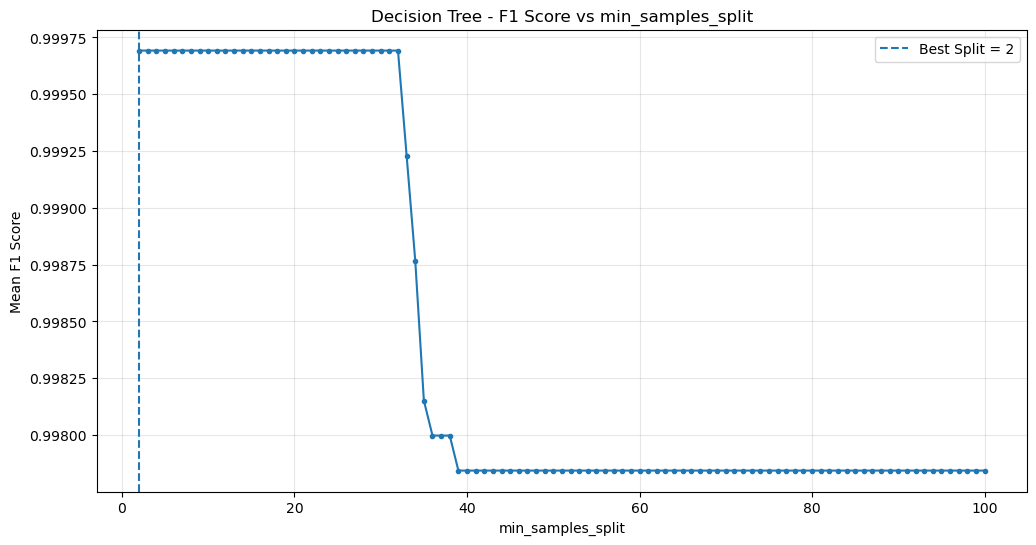


FINAL TEST RESULTS
Test F1 Score: 1.0

Classification Report:
              precision    recall  f1-score   support

           e       1.00      1.00      1.00       842
           p       1.00      1.00      1.00       783

    accuracy                           1.00      1625
   macro avg       1.00      1.00      1.00      1625
weighted avg       1.00      1.00      1.00      1625



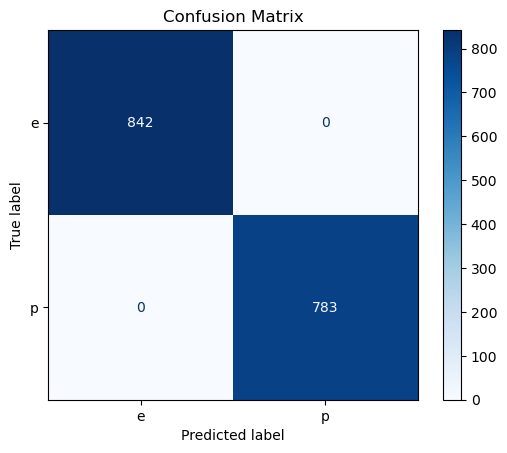


Results saved to f1_results.csv

Process completed successfully!


In [ ]:

# ==========================================
# Decision Tree Classification - Mushrooms
# Hyperparameter Optimization using F1 Score
# ==========================================

# 1. Import Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score
)

from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)


# ==========================================
# 2. Load Dataset
# ==========================================

BASE_DIR = Path.cwd()


DATA_PATH = BASE_DIR / "data" / "mushrooms.csv"



df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())


# ==========================================
# 3. Data Preparation
# ==========================================

TARGET = "class"

X = df.drop(columns=[TARGET])
y = df[TARGET]

categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()


try:
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=True
    )
except TypeError:
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse=True
    )

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            encoder,
            categorical_features
        )
    ]
)


# ==========================================
# 4. Train-Test Split
# ==========================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))


# ==========================================
# 5. Cross Validation Setup
# ==========================================

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


split_values = range(2, 101)

results = []


# ==========================================
# 6. Find Best min_samples_split
# ==========================================

for split in split_values:

    model = Pipeline(
        steps=[
            ("preprocessor", preprocessor),

            (
                "classifier",
                DecisionTreeClassifier(
                    criterion="gini",
                    min_samples_split=split,
                    random_state=42
                )
            )
        ]
    )

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="f1_macro",
        n_jobs=-1
    )

    results.append({
        "min_samples_split": split,
        "mean_f1": scores.mean(),
        "std_f1": scores.std()
    })


# ==========================================
# 7. Results
# ==========================================

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by=["mean_f1", "min_samples_split"],
    ascending=[False, True]
).reset_index(drop=True)

best_split = int(
    results_df.iloc[0]["min_samples_split"]
)

best_f1 = results_df.iloc[0]["mean_f1"]

print("\n================================")
print("BEST RESULT")
print("================================")

print("Best min_samples_split:", best_split)
print("Best Cross Validation F1:", best_f1)


# ==========================================
# 8. Plot Results
# ==========================================

plt.figure(figsize=(12, 6))

plt.plot(
    results_df["min_samples_split"],
    results_df["mean_f1"],
    marker="o",
    markersize=3
)

plt.axvline(
    best_split,
    linestyle="--",
    label=f"Best Split = {best_split}"
)

plt.xlabel("min_samples_split")
plt.ylabel("Mean F1 Score")
plt.title("Decision Tree - F1 Score vs min_samples_split")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


# ==========================================
# 9. Train Final Model
# ==========================================

best_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),

        (
            "classifier",
            DecisionTreeClassifier(
                criterion="gini",
                min_samples_split=best_split,
                random_state=42
            )
        )
    ]
)

best_model.fit(X_train, y_train)


# ==========================================
# 10. Test Evaluation
# ==========================================

y_pred = best_model.predict(X_test)

test_f1 = f1_score(
    y_test,
    y_pred,
    average="macro"
)

print("\n================================")
print("FINAL TEST RESULTS")
print("================================")

print("Test F1 Score:", test_f1)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred
    )
)


# ==========================================
# 11. Confusion Matrix
# ==========================================

cm = confusion_matrix(
    y_test,
    y_pred
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=best_model.classes_
)

disp.plot(cmap="Blues")
plt.title("Confusion Matrix")
plt.show()


# ==========================================
# 12. Save Results
# ==========================================

results_df.to_csv(
    BASE_DIR / "f1_results.csv",
    index=False
)

print("\nResults saved to f1_results.csv")

print("\nProcess completed successfully!")
